In [ ]:
%pip install pygad -q

import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

Note: you may need to restart the kernel to use updated packages.


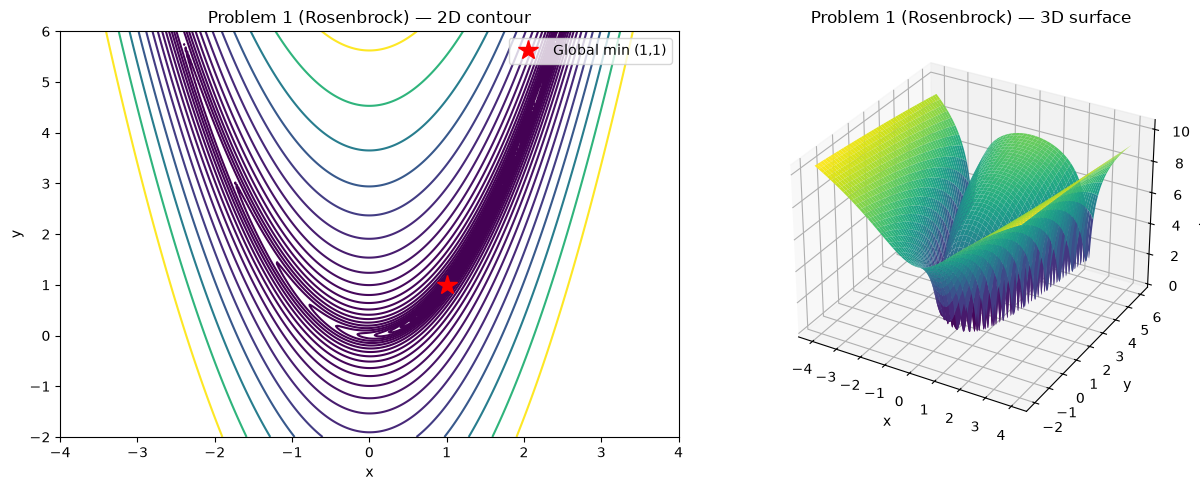

Problem 1 (Rosenbrock)
Analytical global minimum: (x*, y*) = (1.0, 1.0), f(x*,y*) = 0

--- scipy.optimize (Nelder-Mead) ---
Initial guess  Solution (x, y)             f(x*)         Iters   Time (s)  Success
[0, 0]         [1. 1.]                     2.650e-18     110     0.00138   True
[-4, 4]        [1. 1.]                     3.564e-18     165     0.00169   True
[4, 0]         [1. 1.]                     2.175e-17     120     0.00121   True
[-1, -1]       [1. 1.]                     6.307e-18     97      0.00099   True
[2, -3]        [1. 1.]                     7.790e-18     89      0.00092   True

--- pygad.GA ---
Initial guess  Solution (x, y)             f(x*)         Gens    Time (s)  
[0, 0]         [1.021716 1.044162]         4.783e-04     300     0.14456   


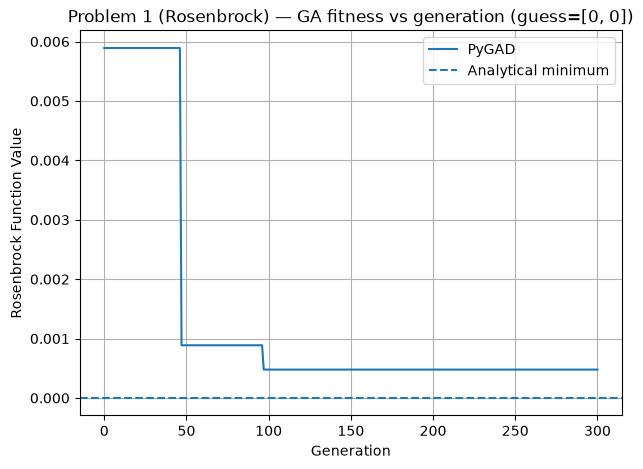

[-4, 4]        [0.867612 0.755465]         1.826e-02     300     0.11183   


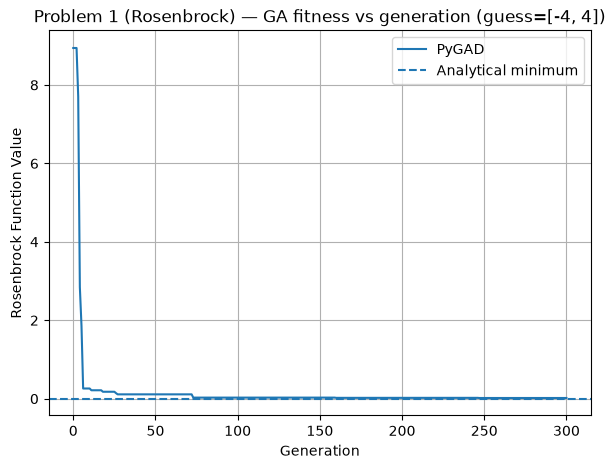

[4, 0]         [0.944137 0.890628]         3.179e-03     300     0.08913   


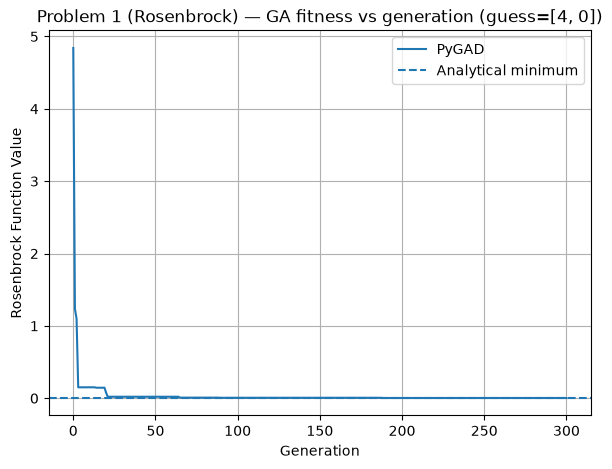

[-1, -1]       [0.988688 0.976892]         1.655e-04     300     0.09496   


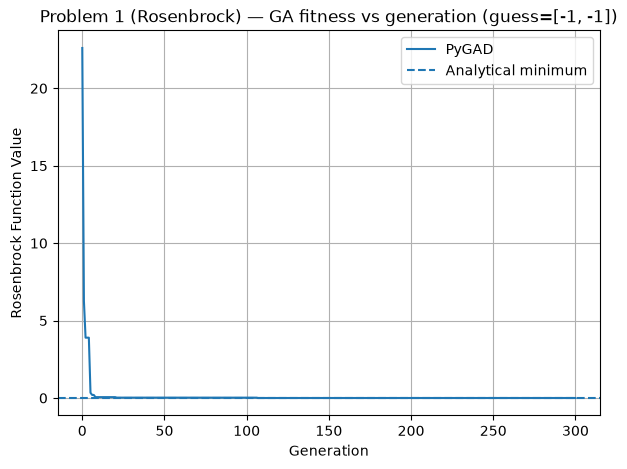

[2, -3]        [0.980193 0.959424]         5.760e-04     300     0.09882   


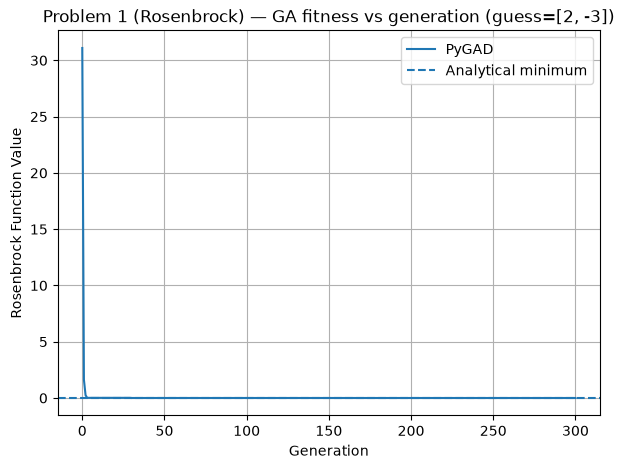


--- Performance comparison: Problem 1 (Rosenbrock) ---
Method        Avg time (s)    Avg iters/gens    Best |f(x*)|
scipy         0.00124         116.2             2.650e-18
pygad GA      0.10786         300.0             1.655e-04


In [2]:


# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2


# 2D & 3D plots
x_range = np.linspace(-4, 4, 400)
y_range = np.linspace(-2, 6, 400)

X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(13, 5))

ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=np.logspace(-1, 3.5, 25), cmap='viridis')
ax1.plot(1, 1, 'r*', markersize=15, label='Global min (1,1)')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Problem 1 (Rosenbrock) — 2D contour')
ax1.legend()

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, np.log1p(Z), cmap='viridis',
                 linewidth=0, antialiased=True)
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('log(1+f)')
ax2.set_title('Problem 1 (Rosenbrock) — 3D surface')

plt.tight_layout()
plt.show()

print("=" * 78)
print("Problem 1 (Rosenbrock)")
print("=" * 78)
print("Analytical global minimum: (x*, y*) = (1.0, 1.0), f(x*,y*) = 0")


# Scipy Optimization
init_guesses = [
    [0, 0],
    [-4, 4],
    [4, 0],
    [-1, -1],
    [2, -3]
]

print("\n--- scipy.optimize (Nelder-Mead) ---")
print(f"{'Initial guess':<15}{'Solution (x, y)':<28}{'f(x*)':<14}{'Iters':<8}{'Time (s)':<10}{'Success'}")

scipy_results = []

for guess in init_guesses:

    start_time = time.time()

    result = minimize(
        rosenbrock,
        guess,
        method='Nelder-Mead',
        options={
            'xatol': 1e-8,
            'fatol': 1e-8,
            'maxiter': 5000
        }
    )

    end_time = time.time()
    elapsed_time = end_time - start_time

    scipy_results.append({
        'guess': guess,
        'x': result.x,
        'f': result.fun,
        'iters': result.nit,
        'time': elapsed_time,
        'success': result.success
    })

    print(
        f"{str(guess):<15}"
        f"{str(np.round(result.x, 6)):<28}"
        f"{result.fun:<14.3e}"
        f"{result.nit:<8}"
        f"{elapsed_time:<10.5f}"
        f"{result.success}"
    )


# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return 1.0 / (rosenbrock(solution) + 1e-12)


print("\n--- pygad.GA ---")
print(f"{'Initial guess':<15}{'Solution (x, y)':<28}{'f(x*)':<14}{'Gens':<8}{'Time (s)':<10}")

ga_results = []

for guess in init_guesses:

    start_time = time.time()

    ga_instance = pygad.GA(
        num_generations=300,
        num_parents_mating=10,
        fitness_func=fitness_func,
        sol_per_pop=60,
        num_genes=2,
        gene_space=[
            {'low': guess[0] - 5, 'high': guess[0] + 5},
            {'low': guess[1] - 5, 'high': guess[1] + 5}
        ],
        mutation_percent_genes=15,
        suppress_warnings=True
    )

    ga_instance.run()

    end_time = time.time()
    elapsed_time = end_time - start_time

    solution, solution_fitness, _ = ga_instance.best_solution()

    val = rosenbrock(solution)
    iters = ga_instance.generations_completed

    ga_results.append({
        'guess': guess,
        'x': solution,
        'f': val,
        'gens': iters,
        'time': elapsed_time
    })

    print(
        f"{str(guess):<15}"
        f"{str(np.round(solution, 6)):<28}"
        f"{val:<14.3e}"
        f"{iters:<8}"
        f"{elapsed_time:<10.5f}"
    )

    # Fitness plot
    fitness = np.array(ga_instance.best_solutions_fitness)
    objective = 1.0 / fitness

    plt.figure(figsize=(7, 5))
    plt.plot(objective, label="PyGAD")
    plt.axhline(y=0, linestyle='--', label="Analytical minimum")
    plt.xlabel("Generation")
    plt.ylabel("Rosenbrock Function Value")
    plt.title(f"Problem 1 (Rosenbrock) — GA fitness vs generation (guess={guess})")
    plt.legend()
    plt.grid(True)
    plt.show()


# Performance comparison
print("\n--- Performance comparison: Problem 1 (Rosenbrock) ---")
print(f"{'Method':<14}{'Avg time (s)':<16}{'Avg iters/gens':<18}{'Best |f(x*)|'}")

avg_time_s = np.mean([r['time'] for r in scipy_results])
avg_it_s = np.mean([r['iters'] for r in scipy_results])
best_f_s = min(r['f'] for r in scipy_results)

avg_time_g = np.mean([r['time'] for r in ga_results])
avg_it_g = np.mean([r['gens'] for r in ga_results])
best_f_g = min(r['f'] for r in ga_results)

print(f"{'scipy':<14}{avg_time_s:<16.5f}{avg_it_s:<18.1f}{best_f_s:.3e}")
print(f"{'pygad GA':<14}{avg_time_g:<16.5f}{avg_it_g:<18.1f}{best_f_g:.3e}")

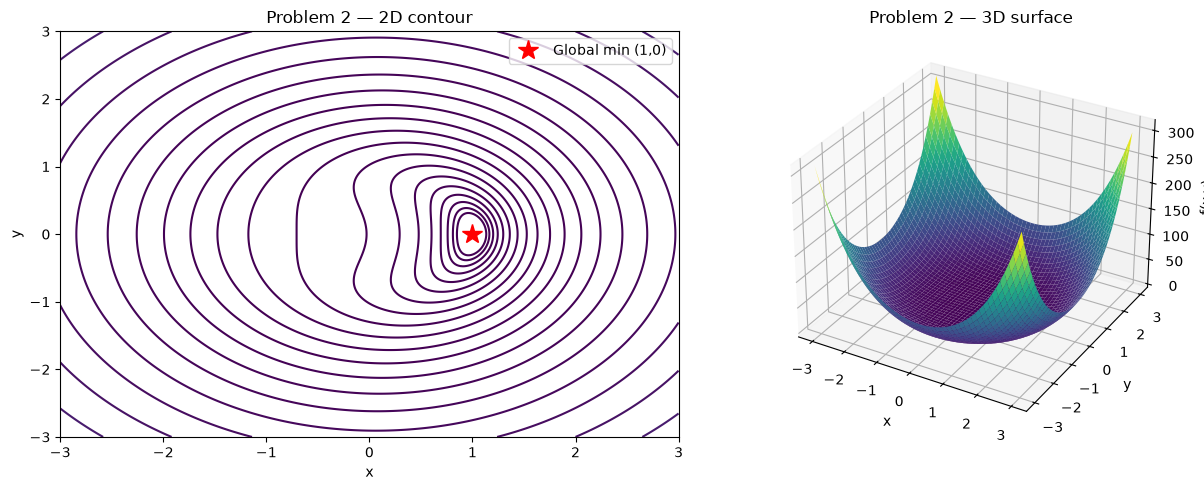

Problem 2
Analytical global minimum: (x*, y*) = (1.0, 0.0), f(x*,y*) = 0

--- scipy.optimize (BFGS) ---
Initial guess  Solution (x, y)             f(x*)         Iters   Time (s)  Success
[0, 0]         [ 1. -0.]                   5.950e-15     3       0.00052   True
[-4, 4]        [1. 0.]                     5.220e-15     18      0.00273   True
[4, 0]         [1. 0.]                     1.567e-13     10      0.00069   True
[-2, -2]       [ 1. -0.]                   2.157e-14     15      0.00116   True
[2, -3]        [1. 0.]                     4.354e-15     15      0.00095   True

--- pygad.GA ---
Initial guess  Solution (x, y)             f(x*)         Gens    Time (s)  
[0, 0]         [ 0.999422 -0.001517]       3.964e-06     300     0.09959   


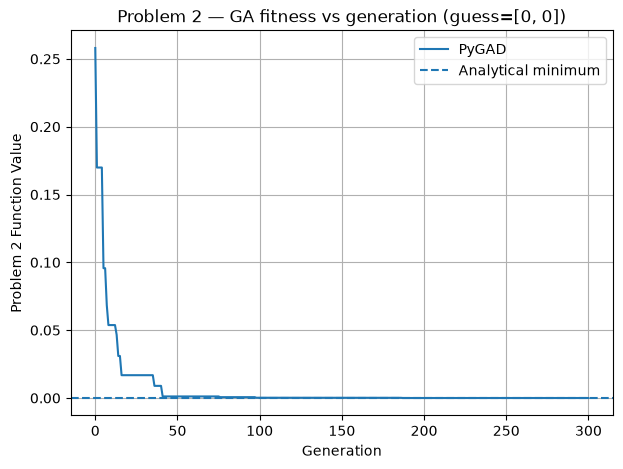

[-4, 4]        [ 0.998993 -0.009474]       9.446e-05     300     0.12811   


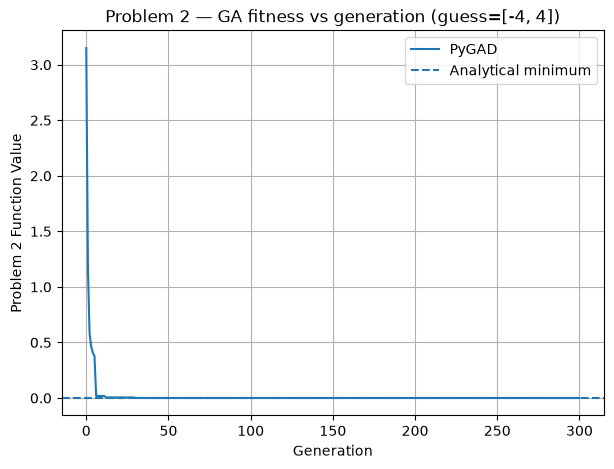

[4, 0]         [ 1.004072e+00 -1.160000e-04]8.320e-05     300     0.09693   


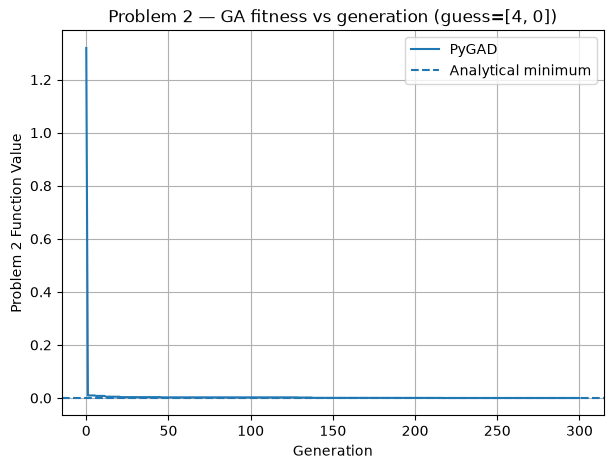

[-2, -2]       [1.000458e+00 1.340000e-04] 1.068e-06     300     0.09969   


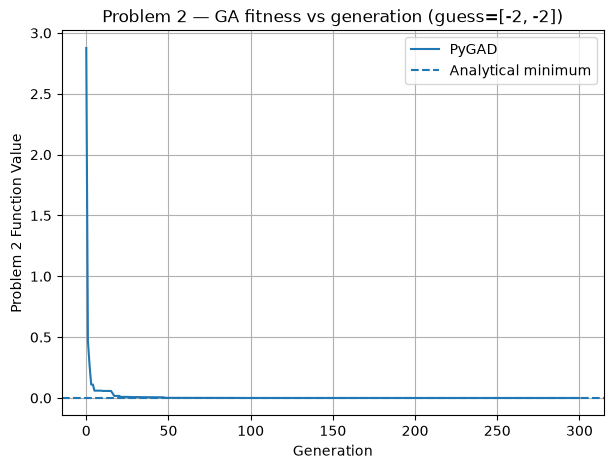

[2, -3]        [ 0.999906 -0.011224]       1.260e-04     300     0.09722   


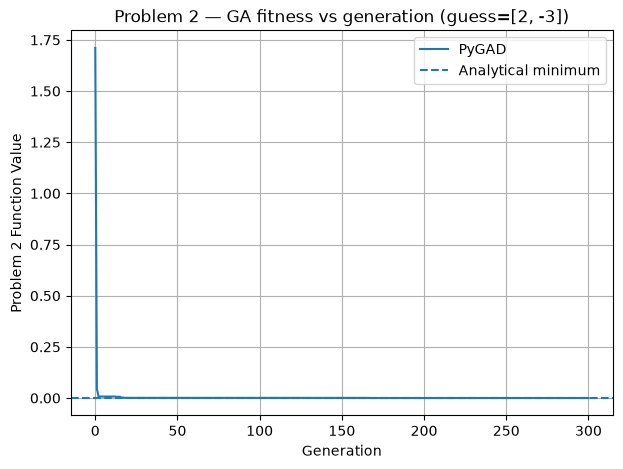


--- Performance comparison: Problem 2 ---
Method        Avg time (s)    Avg iters/gens    Best |f(x*)|
scipy         0.00121         12.2              4.354e-15
pygad GA      0.10431         300.0             1.068e-06


In [3]:


# Define Problem 2 function
def f2(x):
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] - 1)**2 + x[1]**2


# 2D & 3D plots
x_range = np.linspace(-3, 3, 400)
y_range = np.linspace(-3, 3, 400)

X, Y = np.meshgrid(x_range, y_range)
Z = f2([X, Y])

fig = plt.figure(figsize=(13, 5))

ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=np.logspace(-1, 3.5, 25), cmap='viridis')
ax1.plot(1, 0, 'r*', markersize=15, label='Global min (1,0)')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Problem 2 — 2D contour')
ax1.legend()

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='viridis',
                 linewidth=0, antialiased=True)
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('f(x,y)')
ax2.set_title('Problem 2 — 3D surface')

plt.tight_layout()
plt.show()

print("=" * 78)
print("Problem 2")
print("=" * 78)
print("Analytical global minimum: (x*, y*) = (1.0, 0.0), f(x*,y*) = 0")


# Scipy Optimization
init_guesses = [
    [0, 0],
    [-4, 4],
    [4, 0],
    [-2, -2],
    [2, -3]
]

print("\n--- scipy.optimize (BFGS) ---")
print(f"{'Initial guess':<15}{'Solution (x, y)':<28}{'f(x*)':<14}{'Iters':<8}{'Time (s)':<10}{'Success'}")

scipy_results = []

for guess in init_guesses:

    start_time = time.time()

    result = minimize(
        f2,
        guess,
        method='BFGS'
    )

    end_time = time.time()
    elapsed_time = end_time - start_time

    scipy_results.append({
        'guess': guess,
        'x': result.x,
        'f': result.fun,
        'iters': result.nit,
        'time': elapsed_time,
        'success': result.success
    })

    print(
        f"{str(guess):<15}"
        f"{str(np.round(result.x, 6)):<28}"
        f"{result.fun:<14.3e}"
        f"{result.nit:<8}"
        f"{elapsed_time:<10.5f}"
        f"{result.success}"
    )


# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return 1.0 / (f2(solution) + 1e-12)


print("\n--- pygad.GA ---")
print(f"{'Initial guess':<15}{'Solution (x, y)':<28}{'f(x*)':<14}{'Gens':<8}{'Time (s)':<10}")

ga_results = []

for guess in init_guesses:

    start_time = time.time()

    ga_instance = pygad.GA(
        num_generations=300,
        num_parents_mating=10,
        fitness_func=fitness_func2,
        sol_per_pop=60,
        num_genes=2,
        gene_space=[
            {'low': guess[0] - 5, 'high': guess[0] + 5},
            {'low': guess[1] - 5, 'high': guess[1] + 5}
        ],
        mutation_percent_genes=15,
        suppress_warnings=True
    )

    ga_instance.run()

    end_time = time.time()
    elapsed_time = end_time - start_time

    solution, solution_fitness, _ = ga_instance.best_solution()

    val = f2(solution)
    iters = ga_instance.generations_completed

    ga_results.append({
        'guess': guess,
        'x': solution,
        'f': val,
        'gens': iters,
        'time': elapsed_time
    })

    print(
        f"{str(guess):<15}"
        f"{str(np.round(solution, 6)):<28}"
        f"{val:<14.3e}"
        f"{iters:<8}"
        f"{elapsed_time:<10.5f}"
    )

    # Fitness plot
    fitness = np.array(ga_instance.best_solutions_fitness)
    objective = 1.0 / fitness

    plt.figure(figsize=(7, 5))
    plt.plot(objective, label="PyGAD")
    plt.axhline(y=0, linestyle='--', label="Analytical minimum")
    plt.xlabel("Generation")
    plt.ylabel("Problem 2 Function Value")
    plt.title(f"Problem 2 — GA fitness vs generation (guess={guess})")
    plt.legend()
    plt.grid(True)
    plt.show()


# Performance comparison
print("\n--- Performance comparison: Problem 2 ---")
print(f"{'Method':<14}{'Avg time (s)':<16}{'Avg iters/gens':<18}{'Best |f(x*)|'}")

avg_time_s = np.mean([r['time'] for r in scipy_results])
avg_it_s = np.mean([r['iters'] for r in scipy_results])
best_f_s = min(r['f'] for r in scipy_results)

avg_time_g = np.mean([r['time'] for r in ga_results])
avg_it_g = np.mean([r['gens'] for r in ga_results])
best_f_g = min(r['f'] for r in ga_results)

print(f"{'scipy':<14}{avg_time_s:<16.5f}{avg_it_s:<18.1f}{best_f_s:.3e}")
print(f"{'pygad GA':<14}{avg_time_g:<16.5f}{avg_it_g:<18.1f}{best_f_g:.3e}")